# Noria · 07 — Final evaluation on the test set (experiment E16)

Pre-registered in `docs/experiments.md` (commit "Pre-register final evaluation and freeze models").
The final models are used **as they are**, frozen in `reports/final/manifest.json` (SHA-256 checked below):
no retraining, no tuning, no threshold change. **The test set is used once.** Any surprising result is
documented as a limitation, never corrected by modifying the models.

Every measure is computed with the same code (`src/final.py`) on the validation set and on the test set.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, data, analysis, final

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / name, dpi=120, bbox_inches="tight")
    print(f"Figure saved: reports/figures/{name}")

def fmt_auc(a):
    return f"{a['roc_auc']:.4f} [{a['ci_low']:.4f}, {a['ci_high']:.4f}]"

## 1. Frozen models: SHA-256 check

In [2]:
manifest, checks = final.verify_manifest()
display(pd.Series(checks, name="SHA-256 matches the manifest").to_frame())
models = final.load_frozen_models()
print({name: f"{m['n_features']} features, {m['n_estimators']} trees, {m['calibration']}" for name, m in manifest["models"].items()})

,SHA-256 matches the manifest
models/calibrated__lgbm__bank_no_history.joblib,True
models/calibrated__lgbm__bank_with_history.joblib,True
models/calibrated__lgbm__client.joblib,True
data/processed/train.parquet,True
data/processed/val.parquet,True
data/processed/test.parquet,True


{'bank_no_history': '52 features, 392 trees, platt', 'bank_with_history': '65 features, 822 trees, platt', 'client': '7 features, 218 trees, platt'}


## 2. Open the test set (once)

`REPRODUCE_E16` stays `False`: after this run, `reports/final/TEST_USED` exists and loading the test set again
requires `reproduce_e16=True`, reserved for reproducing E16 exactly as it was run.

In [3]:
REPRODUCE_E16 = False
_, val = data.load_train_val()
test = data.load_split("test", final=True, reproduce_e16=REPRODUCE_E16)
ids_with_bureau = analysis.bureau_ids()
print(f"validation: {len(val):,} rows · test: {len(test):,} rows, {int(test[config.TARGET].sum()):,} defaults")

validation: 41,735 rows · test: 41,735 rows, 3,483 defaults


In [4]:
val_out, val_preds = final.evaluate_split(val, models, ids_with_bureau)
test_out, test_preds = final.evaluate_split(test, models, ids_with_bureau)
final.save_json(val_out, "e16_validation")
final.save_json(test_out, "e16_test")
if not REPRODUCE_E16:
    print("Recorded:", data.mark_test_used().read_text().strip())

Recorded: 2026-11-18T20:04:27 · E16 final evaluation


## 3. Headline metrics: validation vs test

In [5]:
headline = pd.DataFrame([
    {"model": name, "features": manifest["models"][name]["n_features"],
     "val ROC-AUC [95% CI]": fmt_auc(val_out["models"][name]["roc_auc"]),
     "test ROC-AUC [95% CI]": fmt_auc(test_out["models"][name]["roc_auc"]),
     "val PR-AUC": round(val_out["models"][name]["pr_auc"], 4), "test PR-AUC": round(test_out["models"][name]["pr_auc"], 4),
     "val Brier": round(val_out["models"][name]["brier_calibrated"], 5), "test Brier": round(test_out["models"][name]["brier_calibrated"], 5),
     "test mean calibrated p": round(test_out["models"][name]["mean_calibrated_p"], 4)}
    for name in final.LISTS
]).set_index("model")
print(f"Default rate: validation {val_out['default_rate']:.4f} · test {test_out['default_rate']:.4f}")
headline

Default rate: validation 0.0835 · test 0.0835


,features,val ROC-AUC [95% CI],test ROC-AUC [95% CI],val PR-AUC,test PR-AUC,val Brier,test Brier,test mean calibrated p
model,,,,,,,,
bank_no_history,52,"0.7091 [0.6990, 0.7177]","0.7067 [0.6979, 0.7156]",0.1933,0.1879,0.07251,0.07274,0.0840
bank_with_history,65,"0.7663 [0.7580, 0.7741]","0.7657 [0.7579, 0.7741]",0.2628,0.2555,0.06906,0.06934,0.0839
client,7,"0.6207 [0.6107, 0.6307]","0.6188 [0.6091, 0.6290]",0.1265,0.1246,0.07538,0.07544,0.0837


Figure saved: reports/figures/19_final_calibration_val_vs_test.png


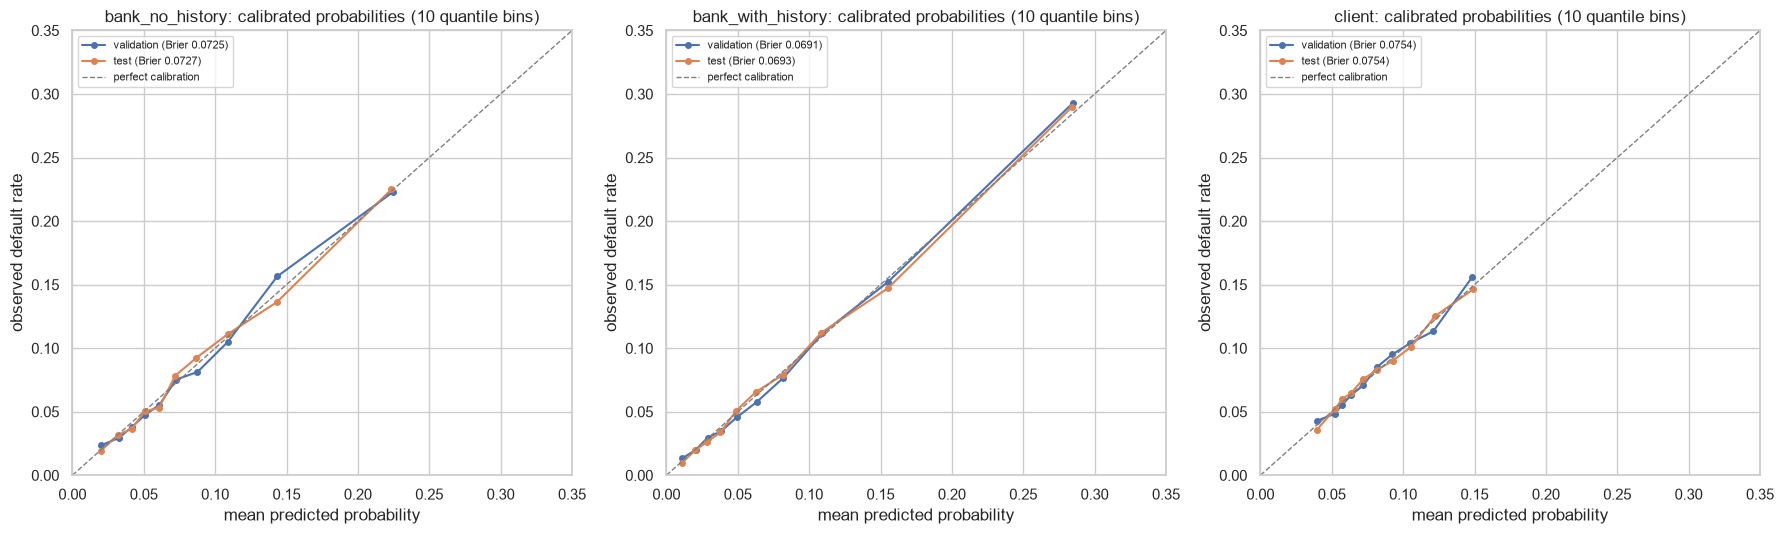

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, name in zip(axes, final.LISTS):
    for split, o in [("validation", val_out), ("test", test_out)]:
        c = o["models"][name]["calibration_curve"]
        ax.plot(c["mean_predicted"], c["observed"], marker="o", ms=4, lw=1.5,
                label=f"{split} (Brier {o['models'][name]['brier_calibrated']:.4f})")
    ax.plot([0, 0.35], [0, 0.35], color="grey", ls="--", lw=1, label="perfect calibration")
    ax.set_xlim(0, 0.35); ax.set_ylim(0, 0.35)
    ax.set_title(f"{name}: calibrated probabilities (10 quantile bins)")
    ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed default rate"); ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "19_final_calibration_val_vs_test.png")
plt.show()

## 4. E2 (cost of the history) and E5 (clients absent from the credit bureau)

In [7]:
for split, o in [("validation", val_out), ("test", test_out)]:
    d = o["e2_with_minus_without"]
    print(f"E2 {split}: with - without history = {d['auc_diff']:+.4f} [{d['ci_low']:+.4f}, {d['ci_high']:+.4f}]")
print()
for split, o in [("validation", val_out), ("test", test_out)]:
    e5 = o["e5"]
    print(f"E5 {split}: {e5['subgroup_rows']:,} clients without bureau record ({e5['subgroup_share']:.1%}), "
          f"default rate {e5['subgroup_default_rate']:.2%} vs {e5['others_default_rate']:.2%}")
pd.DataFrame([{"model": name,
               "val all": fmt_auc(val_out["e5"]["models"][name]["all"]),
               "val no bureau record": fmt_auc(val_out["e5"]["models"][name]["no_bureau_record"]),
               "test all": fmt_auc(test_out["e5"]["models"][name]["all"]),
               "test no bureau record": fmt_auc(test_out["e5"]["models"][name]["no_bureau_record"])}
              for name in final.LISTS]).set_index("model")

E2 validation: with - without history = +0.0572 [+0.0509, +0.0644]
E2 test: with - without history = +0.0590 [+0.0527, +0.0658]

E5 validation: 5,861 clients without bureau record (14.0%), default rate 10.82% vs 7.94%
E5 test: 5,880 clients without bureau record (14.1%), default rate 10.26% vs 8.03%


,val all,val no bureau record,test all,test no bureau record
model,,,,
bank_no_history,"0.7091 [0.6990, 0.7177]","0.7174 [0.6958, 0.7396]","0.7067 [0.6979, 0.7156]","0.6962 [0.6746, 0.7182]"
bank_with_history,"0.7663 [0.7580, 0.7741]","0.7555 [0.7347, 0.7741]","0.7657 [0.7579, 0.7741]","0.7357 [0.7157, 0.7574]"
client,"0.6207 [0.6107, 0.6307]","0.6240 [0.6001, 0.6474]","0.6188 [0.6091, 0.6290]","0.6241 [0.6032, 0.6470]"


## 5. E14 — Risk classes (calibrated probabilities)

In [8]:
for name in ["bank_no_history", "client"]:
    rows = []
    for split, o in [("validation", val_out), ("test", test_out)]:
        for r in o["e14"][name]["classes"]:
            rows.append({"split": split, "class": r["class"], "label": r["label"], "clients": r["clients"],
                         "share (%)": round(r["share"] * 100, 2), "actual default rate (%)": round(r["default_rate"] * 100, 2)})
    print(f"=== {name} · test checks: {test_out['e14'][name]['checks']}")
    display(pd.DataFrame(rows).pivot_table(index=["class", "label"], columns="split",
                                           values=["share (%)", "actual default rate (%)"]).reindex(["low", "medium", "high"], level=0))

=== bank_no_history · test checks: {'max_class_share': 0.44792140888942134, 'class_over_80_percent': False, 'empty_classes': [], 'default_rates_increase': True, 'limitation': False}


actual default rate (%)            share (%)           
split                                            test validation      test validation
class  label                                                                         
low    accept                                    3.14       3.25     34.26      33.83
medium accept with conditions                    7.91       7.38     44.79      45.22
high   refuse                                   17.80      18.66     20.94      20.94

=== client · test checks: {'max_class_share': 0.7286689828680963, 'class_over_80_percent': False, 'empty_classes': [], 'default_rates_increase': True, 'limitation': False}


actual default rate (%)            share (%)           
split                                   test validation      test validation
class  label                                                                
low    favorable                        3.77       4.50     11.11      11.40
medium to strengthen                    7.78       7.72     72.87      73.14
high   fragile                         14.09      14.16     16.02      15.47

## 6. E6 — AUC by employment type and by age group (test)

In [9]:
for name in ["bank_no_history", "client"]:
    for kind in ["income_type", "age"]:
        t = pd.DataFrame(test_out["e6"][name][kind]).set_index("group")
        v = pd.DataFrame(val_out["e6"][name][kind]).set_index("group")
        t["val roc_auc"] = v["roc_auc"]
        print(f"=== {name} by {kind} (test)")
        display(t[["rows", "defaults", "too_small", "roc_auc", "ci_low", "ci_high", "val roc_auc"]].round(4))

=== bank_no_history by income_type (test)


,rows,defaults,too_small,roc_auc,ci_low,ci_high,val roc_auc
group,,,,,,,
Commercial associate,9398,751,False,0.6942,0.6760,0.7128,0.6944
Other,3,1,True,0.5000,0.0000,1.0000,0.5000
Pensioner,7808,439,False,0.6590,0.6324,0.6862,0.6571
State servant,2917,174,False,0.7181,0.6784,0.7569,0.7044
Working,21609,2118,False,0.7053,0.6942,0.7160,0.7066


=== bank_no_history by age (test)


,rows,defaults,too_small,roc_auc,ci_low,ci_high,val roc_auc
group,,,,,,,
20-25,1327,189,False,0.6345,0.5955,0.6759,0.6995
25-35,9690,1066,False,0.6778,0.6608,0.6930,0.7043
35-45,11515,1013,False,0.7087,0.6921,0.7243,0.6970
45-55,9715,694,False,0.7136,0.6934,0.7338,0.6925
55-70,9488,521,False,0.6709,0.6469,0.6946,0.6704
20-35 (aggregate),11017,1255,False,0.6745,0.6590,0.6893,0.7047


=== client by income_type (test)


,rows,defaults,too_small,roc_auc,ci_low,ci_high,val roc_auc
group,,,,,,,
Commercial associate,9398,751,False,0.5971,0.5781,0.6174,0.5891
Other,3,1,True,1.0000,1.0000,1.0000,0.1250
Pensioner,7808,439,False,0.5695,0.5431,0.5955,0.5550
State servant,2917,174,False,0.6267,0.5833,0.6670,0.5687
Working,21609,2118,False,0.6028,0.5902,0.6156,0.6069


=== client by age (test)


,rows,defaults,too_small,roc_auc,ci_low,ci_high,val roc_auc
group,,,,,,,
20-25,1327,189,False,0.5166,0.4687,0.5599,0.5910
25-35,9690,1066,False,0.5817,0.5645,0.5994,0.5911
35-45,11515,1013,False,0.5932,0.5764,0.6108,0.5894
45-55,9715,694,False,0.6027,0.5805,0.6232,0.5865
55-70,9488,521,False,0.5728,0.5476,0.5970,0.5779
20-35 (aggregate),11017,1255,False,0.5774,0.5610,0.5934,0.5921


## 7. E9 — Fairness (test; acceptance = class "low")

In [10]:
for name in ["bank_no_history", "client"]:
    for attr in ["CODE_GENDER", "age_group"]:
        t = pd.DataFrame(test_out["e9"][name][attr]["by_group"]).set_index("sensitive_feature_0")
        v = pd.DataFrame(val_out["e9"][name][attr]["by_group"]).set_index("sensitive_feature_0")
        t["val acceptance_rate"] = v["acceptance_rate"]
        print(f"=== {name} by {attr} (test) · max gaps: "
              f"{ {k: round(x, 4) for k, x in test_out['e9'][name][attr]['max_gap_between_groups'].items()} }")
        display(t[["rows", "defaults", "acceptance_rate", "val acceptance_rate", "false_negative_rate", "false_positive_rate"]].round(4))

=== bank_no_history by CODE_GENDER (test) · max gaps: {'acceptance_rate': 0.0907, 'false_negative_rate': 0.0554, 'false_positive_rate': 0.0859}


,rows,defaults,acceptance_rate,val acceptance_rate,false_negative_rate,false_positive_rate
sensitive_feature_0,,,,,,
F,27344.0,1967.0,0.3739,0.3673,0.1530,0.6090
M,14391.0,1516.0,0.2832,0.2827,0.0976,0.6949


=== bank_no_history by age_group (test) · max gaps: {'acceptance_rate': 0.4366, 'false_negative_rate': 0.2831, 'false_positive_rate': 0.4369}


,rows,defaults,acceptance_rate,val acceptance_rate,false_negative_rate,false_positive_rate
sensitive_feature_0,,,,,,
20-25,1327.0,189.0,0.0897,0.1000,0.0106,0.8972
25-35,9690.0,1066.0,0.1915,0.1898,0.0675,0.7931
35-45,11515.0,1013.0,0.3165,0.3128,0.1145,0.6641
45-55,9715.0,694.0,0.3796,0.3672,0.1527,0.6029
55-70,9488.0,521.0,0.5262,0.5272,0.2937,0.4602


=== client by CODE_GENDER (test) · max gaps: {'acceptance_rate': 0.0346, 'false_negative_rate': 0.0025, 'false_positive_rate': 0.0355}


,rows,defaults,acceptance_rate,val acceptance_rate,false_negative_rate,false_positive_rate
sensitive_feature_0,,,,,,
F,27344.0,1967.0,0.1230,0.1269,0.0513,0.8714
M,14391.0,1516.0,0.0885,0.0891,0.0488,0.9069


=== client by age_group (test) · max gaps: {'acceptance_rate': 0.2642, 'false_negative_rate': 0.1727, 'false_positive_rate': 0.2695}


,rows,defaults,acceptance_rate,val acceptance_rate,false_negative_rate,false_positive_rate
sensitive_feature_0,,,,,,
20-25,1327.0,189.0,0.0000,0.0000,0.0000,1.0000
25-35,9690.0,1066.0,0.0049,0.0042,0.0019,0.9948
35-45,11515.0,1013.0,0.0580,0.0620,0.0267,0.9390
45-55,9715.0,694.0,0.1457,0.1470,0.0807,0.8494
55-70,9488.0,521.0,0.2642,0.2729,0.1727,0.7305


## 8. Validation vs test, every figure

In [11]:
comparison = final.comparison_table(val_out, test_out)
comparison.to_csv(final.FINAL_DIR / "validation_vs_test.csv", index=False)
print("Saved: reports/final/validation_vs_test.csv ·", len(comparison), "figures")
print("Largest absolute differences:")
display(comparison.assign(abs_diff=comparison["test - validation"].abs()).sort_values("abs_diff", ascending=False).head(12).round(4))
comparison.round(4)

Saved: reports/final/validation_vs_test.csv · 94 figures
Largest absolute differences:


,measure,validation,test,test - validation,abs_diff
63,E6 client Other: AUC,0.1250,1.0000,0.8750,0.8750
67,E6 client 20-25: AUC,0.5910,0.5166,-0.0744,0.0744
29,E6 bank_no_history 20-25: AUC,0.6995,0.6345,-0.0649,0.0649
65,E6 client State servant: AUC,0.5687,0.6267,0.0581,0.0581
34,E6 bank_no_history 20-35 (aggregate): AUC,0.7047,0.6745,-0.0302,0.0302
30,E6 bank_no_history 25-35: AUC,0.7043,0.6778,-0.0265,0.0265
89,E9 client age_group=45-55: false_negative_rate,0.1065,0.0807,-0.0258,0.0258
74,E9 client CODE_GENDER=F: false_negative_rate,0.0738,0.0513,-0.0224,0.0224
92,E9 client age_group=55-70: false_negative_rate,0.1939,0.1727,-0.0212,0.0212
32,E6 bank_no_history 45-55: AUC,0.6925,0.7136,0.0212,0.0212


,measure,validation,test,test - validation
0,bank_no_history: ROC-AUC,0.7091,0.7067,-0.0024
1,bank_no_history: PR-AUC,0.1933,0.1879,-0.0054
2,bank_no_history: Brier (calibrated),0.0725,0.0727,0.0002
3,bank_no_history: mean calibrated p,0.0843,0.0840,-0.0003
4,bank_with_history: ROC-AUC,0.7663,0.7657,-0.0006
5,bank_with_history: PR-AUC,0.2628,0.2555,-0.0073
6,bank_with_history: Brier (calibrated),0.0691,0.0693,0.0003
7,bank_with_history: mean calibrated p,0.0843,0.0839,-0.0004
8,client: ROC-AUC,0.6207,0.6188,-0.0018
9,client: PR-AUC,0.1265,0.1246,-0.0019


## Findings

The test set (41,735 clients, 3,483 defaults, 8.35%) was opened **once**, on 18/11/2026 at 20:04, with the frozen models (all SHA-256 checks passed). Nothing was retrained or adjusted.

1. **Headline metrics, test vs validation** (ROC-AUC [95% CI]):
   - bank without history **0.7067** [0.6979, 0.7156] vs 0.7091;
   - bank with history **0.7657** [0.7579, 0.7741] vs 0.7663;
   - client **0.6188** [0.6091, 0.6290] vs 0.6207.

   PR-AUC 0.1879 / 0.2555 / 0.1246 (validation 0.1933 / 0.2628 / 0.1265). The differences are all within ±0.003 AUC, so the validation estimates were not optimistic.
2. **Calibration holds on the test set**: Brier 0.07274 / 0.06934 / 0.07544 (validation 0.07251 / 0.06906 / 0.07538), and the mean calibrated probability is 0.0840 / 0.0839 / 0.0837 for an actual rate of 0.0835.
3. **E2 — Cost of the history (test)**: **+0.0590** [+0.0527, +0.0658] (validation +0.0572 [+0.0509, +0.0644]).
4. **E5 — Clients absent from `bureau.csv` (test)**: 5,880 clients (14.1%), default rate 10.26% vs 8.03%.
   - Bank without history: **0.6962** [0.6746, 0.7182] vs 0.7067 overall (validation: 0.7174 vs 0.7091).
   - Bank with history: 0.7357 [0.7157, 0.7574] vs 0.7657.
   - Client: 0.6241 [0.6032, 0.6470] vs 0.6188.

   On the test set the model without history is slightly **below** its overall AUC (−0.0105, inside the CI), where it was slightly above on validation. The advantage of the history model still shrinks for these clients: 0.0395 vs 0.0590 overall.
5. **E14 — Classes (test)**:
   - bank without history: accept 34.26% (actual default rate 3.14%), with conditions 44.79% (7.91%), refuse 20.94% (17.80%);
   - client: favorable 11.11% (3.77%), to strengthen 72.87% (7.78%), fragile 16.02% (14.09%).

   The default rates increase and no class exceeds 80%: no limitation triggered.
6. **E6 — Target population (test)**:
   - By employment type, stable: bank without history `Commercial associate` 0.6942 (validation 0.6944), `Working` 0.7053, `State servant` 0.7181, `Pensioner` 0.6590. Client `Commercial associate` 0.5971, `Working` 0.6028.
   - **Young applicants are weaker on the test set**: bank without history 20-25 **0.6345** [0.5955, 0.6759] (validation 0.6995), 25-35 0.6778 (0.7043), **20-35 0.6745** [0.6590, 0.6893] (0.7047).
   - Client 20-25 **0.5166** [0.4687, 0.5599] (validation 0.5910), close to random; 20-35 0.5774 [0.5610, 0.5934].
   - `Other` (3 rows) is too small to conclude.
7. **E9 — Fairness (test)**, consistent with validation:
   - bank without history: acceptance F 37.39% vs M 28.32%; by age 8.97% (20-25) → 52.62% (55-70);
   - client: 0.00% (20-25) and 0.49% (25-35) "favorable" vs 26.42% (55-70).
8. **Largest validation-test differences**: they concern the young age groups (20-25 AUC −0.065 for the bank model, −0.074 for the client model) and the no-history subgroup (−0.021). As pre-registered, they are documented as limitations; the models are not modified.